In [33]:
!pip install git+https://github.com/lucasb-eyer/pydensecrf.git

  Cloning https://github.com/lucasb-eyer/pydensecrf.git to /tmp/pip-req-build-b_dhpcsq
  Running command git clone --filter=blob:none --quiet https://github.com/lucasb-eyer/pydensecrf.git /tmp/pip-req-build-b_dhpcsq
  Resolved https://github.com/lucasb-eyer/pydensecrf.git to commit 2723c7fa4f2ead16ae1ce3d8afe977724bb8f87f
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [34]:
import tensorflow as tf
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
import os
import glob
import cv2
import imageio
import sys
import re

from __future__ import print_function

import numpy as np 
import pandas as pd 
import nibabel as nib
import matplotlib.pyplot as plt

from tqdm.notebook import tqdm
from ipywidgets import *
from PIL import Image
from matplotlib.pyplot import figure

from fastai.basics import *
from fastai.vision.all import *
from fastai.data.transforms import *

import skimage.io as io
import skimage.transform as trans

import tensorflow as tf

from tensorflow.python.keras.optimizers import TFOptimizer
from tensorflow.keras import backend as K
from keras.models import Model
from tensorflow import expand_dims
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from tensorflow.compat.v1 import image
from tensorflow.keras.layers import MaxPooling2D, AveragePooling2D, UpSampling2D, Conv2DTranspose, GlobalAveragePooling2D
from tensorflow.keras.layers import Conv2D, DepthwiseConv2D, Lambda
from tensorflow.keras.layers import BatchNormalization, Activation, concatenate, multiply, add
from tensorflow.keras.layers import ReLU, LeakyReLU, PReLU, ELU, Softmax
from tensorflow import math
from tensorflow.keras.layers import Layer
import tensorflow.keras.backend as K
from tensorflow.nn import depth_to_space
from tensorflow.image import extract_patches
from tensorflow.keras.layers import Conv2D, Layer, Dense, Embedding, Dropout, Conv2D, LayerNormalization
from tensorflow.keras.activations import softmax
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from keras.layers import *
from keras.optimizers import *
from keras.callbacks import ModelCheckpoint, LearningRateScheduler
from keras import backend as keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.model_selection import train_test_split

In [35]:

# Directories
image_dir = '/kaggle/input/datasets/ag3ntsp1d3rx/litsdataset2/images'
mask_dir = '/kaggle/input/datasets/ag3ntsp1d3rx/litsdataset2/masks'

image_filenames = sorted(os.listdir(image_dir))
mask_filenames = sorted(os.listdir(mask_dir))

print(image_filenames[:3])
print(mask_filenames[:3])

# Split the filenames into training and validation sets
train_images, val_images, train_masks, val_masks = train_test_split(
    image_filenames, mask_filenames, test_size=0.2, random_state=42
)

def image_mask_generator(image_dir, mask_dir, image_filenames, mask_filenames, batch_size, target_size):
    while True:
        # Shuffle the data if you want random batches
        indices = np.arange(len(image_filenames))
        np.random.shuffle(indices)

        for start_idx in range(0, len(image_filenames), batch_size):
            batch_indices = indices[start_idx:start_idx + batch_size]
            batch_images = []
            batch_masks = []

            for i in batch_indices:
                # Load the image and mask
                image = load_img(os.path.join(image_dir, image_filenames[i]), target_size=target_size)
                mask = load_img(os.path.join(mask_dir, mask_filenames[i]), target_size=target_size, color_mode='grayscale')

                # Convert to array
                image = img_to_array(image) / 255.0
                mask = img_to_array(mask) / 255.0

                batch_images.append(image)
                batch_masks.append(mask)

            yield np.array(batch_images), np.array(batch_masks)


['Volume-000-000.png', 'Volume-000-001.png', 'Volume-000-002.png']
['Volume-000-000.png', 'Volume-000-001.png', 'Volume-000-002.png']


In [36]:
len(train_images), len(val_images)

(46910, 11728)

In [37]:
batch_size = 2            # reduced from 12 to save VRAM
target_size = (256, 256)  # reduced from 512×512; change model input_size to match


# Training generator
train_gen = image_mask_generator(image_dir, mask_dir, train_images, train_masks, batch_size, target_size)

# Validation generator
val_gen = image_mask_generator(image_dir, mask_dir, val_images, val_masks, batch_size, target_size)


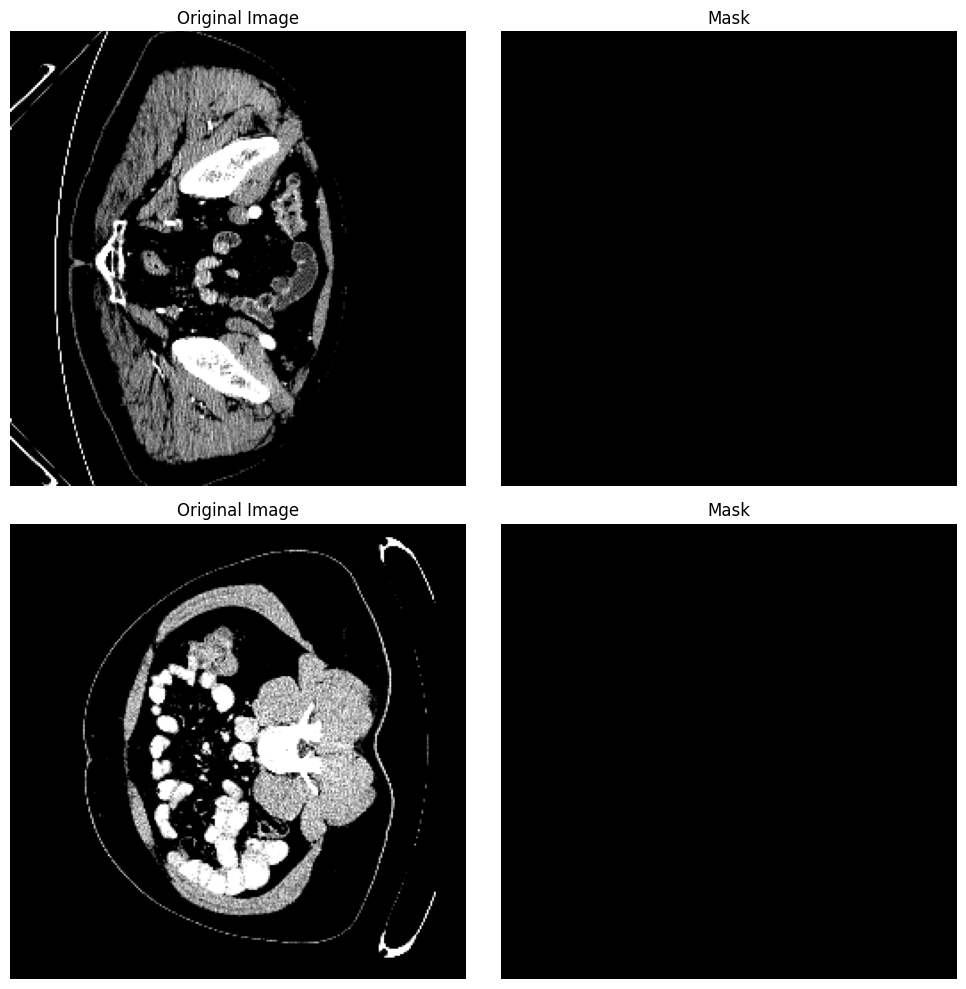

In [38]:
original_images, masks = next(train_gen)

# Number of images to display
num_images = len(original_images)

# Plotting
fig, axes = plt.subplots(num_images, 2, figsize=(10, 5 * num_images))

for i in range(num_images):
    # Display original image
    axes[i, 0].imshow(np.squeeze(original_images[i]), cmap='gray')
    axes[i, 0].set_title('Original Image')
    axes[i, 0].axis('off')
    
    # Display mask
    axes[i, 1].imshow(np.squeeze(masks[i]), cmap='gray')
    axes[i, 1].set_title('Mask')
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

# SWIN-UNET

In [39]:
class patch_extract(Layer):
    '''
    Extract patches from the input feature map.
    
    patches = patch_extract(patch_size)(feature_map)
    
    ----------
    Dosovitskiy, A., Beyer, L., Kolesnikov, A., Weissenborn, D., Zhai, X., Unterthiner, 
    T., Dehghani, M., Minderer, M., Heigold, G., Gelly, S. and Uszkoreit, J., 2020. 
    An image is worth 16x16 words: Transformers for image recognition at scale. 
    arXiv preprint arXiv:2010.11929.
    
    Input
    ----------
        feature_map: a four-dimensional tensor of (num_sample, width, height, channel)
        patch_size: size of split patches (width=height)
        
    Output
    ----------
        patches: a two-dimensional tensor of (num_sample*num_patch, patch_size*patch_size)
                 where `num_patch = (width // patch_size) * (height // patch_size)`
                 
    For further information see: https://www.tensorflow.org/api_docs/python/tf/image/extract_patches
        
    '''
    
    def __init__(self, patch_size, **kwargs):
        super(patch_extract, self).__init__(**kwargs)
        self.patch_size = patch_size
        self.patch_size_x = patch_size[0]
        self.patch_size_y = patch_size[0]
    
    def call(self, images):
        
        batch_size = tf.shape(images)[0]
        
        patches = extract_patches(images=images,
                                  sizes=(1, self.patch_size_x, self.patch_size_y, 1),
                                  strides=(1, self.patch_size_x, self.patch_size_y, 1),
                                  rates=(1, 1, 1, 1), padding='VALID',)
        # patches.shape = (num_sample, patch_num, patch_num, patch_size*channel)
        
        patch_dim = patches.shape[-1]
        patch_num = patches.shape[1]
        patches = tf.reshape(patches, (batch_size, patch_num*patch_num, patch_dim))
        # patches.shape = (num_sample, patch_num*patch_num, patch_size*channel)
        
        return patches
    
    def get_config(self):
        config = super().get_config().copy()
        config.update({'patch_size': self.patch_size,})
        return config
    
    @classmethod
    def from_config(cls, config):
        return cls(**config)
    
class patch_embedding(Layer):
    '''
    Embed patches to tokens.
    
    patches_embed = patch_embedding(num_patch, embed_dim)(pathes)
    
    ----------
    Dosovitskiy, A., Beyer, L., Kolesnikov, A., Weissenborn, D., Zhai, X., Unterthiner, 
    T., Dehghani, M., Minderer, M., Heigold, G., Gelly, S. and Uszkoreit, J., 2020. 
    An image is worth 16x16 words: Transformers for image recognition at scale. 
    arXiv preprint arXiv:2010.11929.
    
    Input
    ----------
        num_patch: number of patches to be embedded.
        embed_dim: number of embedded dimensions. 
        
    Output
    ----------
        embed: Embedded patches.
    
    For further information see: https://keras.io/api/layers/core_layers/embedding/
    
    '''
    
    def __init__(self, num_patch, embed_dim, **kwargs):
        
        super(patch_embedding, self).__init__(**kwargs)
        self.num_patch = num_patch
        self.embed_dim = embed_dim
        self.proj = Dense(embed_dim)
        self.pos_embed = Embedding(input_dim=num_patch, output_dim=embed_dim)

    def get_config(self):
        config = super().get_config().copy()
        config.update({
            'num_patch': self.num_patch,
            'embed_dim': self.embed_dim,
        })
        return config
    
    @classmethod
    def from_config(cls, config):
        return cls(**config)
    
    def call(self, patch):
        pos = tf.range(start=0, limit=self.num_patch, delta=1)
        embed = self.proj(patch) + self.pos_embed(pos)
        return embed

class patch_merging(tf.keras.layers.Layer):
    '''
    Downsample embedded patches; it halfs the number of patches
    and double the embedded dimensions (c.f. pooling layers).
    
    Input
    ----------
        num_patch: number of patches to be embedded.
        embed_dim: number of embedded dimensions. 
        
    Output
    ----------
        x: downsampled patches.
    
    '''
    def __init__(self, num_patch, embed_dim, name='', **kwargs):
        super(patch_merging, self).__init__(**kwargs)
        
        self.num_patch = num_patch
        self.embed_dim = embed_dim
        
        # A linear transform that doubles the channels 
        self.linear_trans = Dense(2*embed_dim, use_bias=False, name='{}_linear_trans'.format(name))

    def get_config(self):
        config = super().get_config().copy()
        config.update({
            'num_patch': self.num_patch,
            'embed_dim': self.embed_dim,
            'name':self.name
        })
        return config

    @classmethod
    def from_config(cls, config):
        return cls(**config)
    
    def call(self, x):
        
        H, W = self.num_patch
        B, L, C = x.get_shape().as_list()
        
        assert (L == H * W), 'input feature has wrong size'
        assert (H % 2 == 0 and W % 2 == 0), '{}-by-{} patches received, they are not even.'.format(H, W)
        
        # Convert the patch sequence to aligned patches
        x = tf.reshape(x, shape=(-1, H, W, C))
        
        # Downsample
        x0 = x[:, 0::2, 0::2, :]  # B H/2 W/2 C
        x1 = x[:, 1::2, 0::2, :]  # B H/2 W/2 C
        x2 = x[:, 0::2, 1::2, :]  # B H/2 W/2 C
        x3 = x[:, 1::2, 1::2, :]  # B H/2 W/2 C
        x = tf.concat((x0, x1, x2, x3), axis=-1)
        
        # Convert to the patch squence
        x = tf.reshape(x, shape=(-1, (H//2)*(W//2), 4*C))
       
        # Linear transform
        x = self.linear_trans(x)

        return x

class patch_expanding(tf.keras.layers.Layer):
    '''
    Upsample embedded patches with a given rate (e.g., x2, x4, x8, ...) 
    the number of patches is increased, and the embedded dimensions are reduced.
    
    Input
    ----------
        num_patch: number of patches.
        embed_dim: number of embedded dimensions.
        upsample_rate: the factor of patches expanding, 
                       e.g., upsample_rate=2 doubles input patches and halfs embedded dimensions.
        return_vector: the indicator of returning a sequence of tokens (return_vector=True)  
                       or two-dimentional, spatially aligned tokens (return_vector=False)
                       
    For further information see: https://www.tensorflow.org/api_docs/python/tf/nn/depth_to_space
    '''

    def __init__(self, num_patch, embed_dim, upsample_rate, return_vector=True, name='patch_expand', **kwargs):
        super(patch_expanding, self).__init__(**kwargs)
        
        self.num_patch = num_patch
        self.embed_dim = embed_dim
        self.upsample_rate = upsample_rate
        self.return_vector = return_vector
        
        # Linear transformations that doubles the channels 
        self.linear_trans1 = Conv2D(upsample_rate*embed_dim, kernel_size=1, use_bias=False, name='{}_linear_trans1'.format(name))
        # 
        self.linear_trans2 = Conv2D(upsample_rate*embed_dim, kernel_size=1, use_bias=False, name='{}_linear_trans1'.format(name))
        self.prefix = name
        
    def get_config(self):
        config = super().get_config().copy()
        config.update({
            'num_patch': self.num_patch,
            'embed_dim': self.embed_dim,
            'upsample_rate': self.upsample_rate,
            'return_vector': self.return_vector,
            'name':self.name,
        })
        return config

    @classmethod
    def from_config(cls, config):
        return cls(**config)
    
    def call(self, x):
        
        H, W = self.num_patch
        B, L, C = x.get_shape().as_list()
        
        assert (L == H * W), 'input feature has wrong size'

        x = tf.reshape(x, (-1, H, W, C))
        
        x = self.linear_trans1(x)
        
        # rearange depth to number of patches
        x = depth_to_space(x, self.upsample_rate, data_format='NHWC', name='{}_d_to_space'.format(self.prefix))
        
        if self.return_vector:
            # Convert aligned patches to a patch sequence
            x = tf.reshape(x, (-1, L*self.upsample_rate*self.upsample_rate, C//2))

        return x
    
# ========== Swin-Transformer only ========== #
# TODO: documentation.

def window_partition(x, window_size):
    
    # Get the static shape of the input tensor
    # (Sample, Height, Width, Channel)
    _, H, W, C = x.get_shape().as_list()
    
    # Subset tensors to patches
    patch_num_H = H//window_size
    patch_num_W = W//window_size
    x = tf.reshape(x, shape=(-1, patch_num_H, window_size, patch_num_W, window_size, C))
    x = tf.transpose(x, (0, 1, 3, 2, 4, 5))
    
    # Reshape patches to a patch sequence
    windows = tf.reshape(x, shape=(-1, window_size, window_size, C))
    
    return windows

def window_reverse(windows, window_size, H, W, C):
    
    # Reshape a patch sequence to aligned patched 
    patch_num_H = H//window_size
    patch_num_W = W//window_size
    x = tf.reshape(windows, shape=(-1, patch_num_H, patch_num_W, window_size, window_size, C))
    x = tf.transpose(x, perm=(0, 1, 3, 2, 4, 5))
    
    # Merge patches to spatial frames
    x = tf.reshape(x, shape=(-1, H, W, C))
    
    return x

def drop_path_(inputs, drop_prob, is_training):
    
    # Bypass in non-training mode
    if (not is_training) or (drop_prob == 0.):
        return inputs

    # Compute keep_prob
    keep_prob = 1.0 - drop_prob

    # Compute drop_connect tensor
    input_shape = tf.shape(inputs)
    batch_num = input_shape[0]; rank = len(input_shape)
    
    shape = (batch_num,) + (1,) * (rank - 1)
    random_tensor = keep_prob + tf.random.uniform(shape, dtype=inputs.dtype)
    path_mask = tf.floor(random_tensor)
    output = tf.math.divide(inputs, keep_prob) * path_mask
    return output

class drop_path(Layer):
    def __init__(self, drop_prob=None, **kwargs):
        super(drop_path, self).__init__(**kwargs)
        self.drop_prob = drop_prob

    def get_config(self):
        config = super().get_config().copy()
        config.update({'drop_prob': self.drop_prob})
        return config

    @classmethod
    def from_config(cls, config):
        return cls(**config)
    
    def call(self, x, training=None):
        return drop_path_(x, self.drop_prob, training)

class Mlp(tf.keras.layers.Layer):
    def __init__(self, filter_num, drop=0., name='mlp', **kwargs):
        
        super(Mlp, self).__init__(**kwargs)
        
        self.filter_num = filter_num
        self.drop = drop
        
        # MLP layers
        self.fc1 = Dense(filter_num[0], name='{}_mlp_0'.format(name))
        self.fc2 = Dense(filter_num[1], name='{}_mlp_1'.format(name))
        
        # Dropout layer
        self.drop = Dropout(drop)
        
        # GELU activation
        self.activation = tf.keras.activations.gelu
        
    def get_config(self):
        config = super().get_config().copy()
        config.update({
            'filter_num': self.filter_num,
            'drop': self.drop,
            'name': self.name,
        })
        return config

    @classmethod
    def from_config(cls, config):
        return cls(**config)
    
    def call(self, x):
        
        # MLP --> GELU --> Drop --> MLP --> Drop
        x = self.fc1(x)
        x = self.activation(x)
        x = self.drop(x)
        x = self.fc2(x)
        x = self.drop(x)
        
        return x

class WindowAttention(tf.keras.layers.Layer):
    def __init__(self, dim, window_size, num_heads, qkv_bias=True, qk_scale=None, 
                 attn_drop=0, proj_drop=0., name='swin_atten', **kwargs):
        super(WindowAttention, self).__init__(**kwargs)
        
        self.dim = dim # number of input dimensions
        self.window_size = window_size # size of the attention window
        self.num_heads = num_heads # number of self-attention heads
        self.qkv_bias = qkv_bias
        self.qk_scale = qk_scale
        self.attn_drop = attn_drop
        self.proj_drop = proj_drop
        
        head_dim = dim // num_heads
        self.scale = qk_scale or head_dim ** -0.5 # query scaling factor
        
        self.prefix = name
        
        # Layers
        self.qkv = Dense(dim * 3, use_bias=qkv_bias, name='{}_attn_qkv'.format(self.prefix))
        self.attn_drop = Dropout(attn_drop)
        self.proj = Dense(dim, name='{}_attn_proj'.format(self.prefix))
        self.proj_drop = Dropout(proj_drop)

    def get_config(self):
        config = super().get_config().copy()
        config.update({
            'dim':self.dim, 
            'window_size':self.window_size, 
            'num_heads':self.num_heads, 
            'qkv_bias':self.qkv_bias, 
            'qk_scale':self.qk_scale, 
            'attn_drop':self.attn_drop, 
            'proj_drop':self.proj_drop, 
            'name':self.prefix
        })
        return config

    @classmethod
    def from_config(cls, config):
        return cls(**config)
        
    def build(self, input_shape):
        
        # zero initialization
        num_window_elements = (2*self.window_size[0] - 1) * (2*self.window_size[1] - 1)
        self.relative_position_bias_table = self.add_weight(name='{}_attn_pos'.format(self.prefix),
                                                            shape=(num_window_elements, self.num_heads),
                                                            initializer='zeros', trainable=True)
        
        # Indices of relative positions
        coords_h = np.arange(self.window_size[0])
        coords_w = np.arange(self.window_size[1])
        coords_matrix = np.meshgrid(coords_h, coords_w, indexing='ij')
        coords = np.stack(coords_matrix)
        coords_flatten = coords.reshape(2, -1)
        relative_coords = coords_flatten[:, :, None] - coords_flatten[:, None, :]
        relative_coords = relative_coords.transpose([1, 2, 0])
        relative_coords[:, :, 0] += self.window_size[0] - 1
        relative_coords[:, :, 1] += self.window_size[1] - 1
        relative_coords[:, :, 0] *= 2 * self.window_size[1] - 1
        relative_position_index = relative_coords.sum(-1)
        
        with tf.init_scope():
            # convert to the tf variable
            self.relative_position_index = tf.Variable(
                initial_value=tf.convert_to_tensor(relative_position_index), trainable=False, name='{}_attn_pos_ind'.format(self.prefix))
        
        self.built = True

    def call(self, x, mask=None):
        
        # Get input tensor static shape
        _, N, C = x.get_shape().as_list()
        head_dim = C//self.num_heads
        
        x_qkv = self.qkv(x)
        x_qkv = tf.reshape(x_qkv, shape=(-1, N, 3, self.num_heads, head_dim))
        x_qkv = tf.transpose(x_qkv, perm=(2, 0, 3, 1, 4))
        q, k, v = x_qkv[0], x_qkv[1], x_qkv[2]
        
        # Query rescaling
        q = q * self.scale
        
        # multi-headed self-attention
        k = tf.transpose(k, perm=(0, 1, 3, 2))
        attn = (q @ k)
        
        # Shift window
        num_window_elements = self.window_size[0] * self.window_size[1]
        relative_position_index_flat = tf.reshape(self.relative_position_index, shape=(-1,))
        relative_position_bias = tf.gather(self.relative_position_bias_table, relative_position_index_flat)
        relative_position_bias = tf.reshape(relative_position_bias, shape=(num_window_elements, num_window_elements, -1))
        relative_position_bias = tf.transpose(relative_position_bias, perm=(2, 0, 1))
        attn = attn + tf.expand_dims(relative_position_bias, axis=0)

        if mask is not None:
            nW = mask.get_shape()[0]
            mask_float = tf.cast(tf.expand_dims(tf.expand_dims(mask, axis=1), axis=0), tf.float32)
            attn = tf.reshape(attn, shape=(-1, nW, self.num_heads, N, N)) + mask_float
            attn = tf.reshape(attn, shape=(-1, self.num_heads, N, N))
            attn = softmax(attn, axis=-1)
        else:
            attn = softmax(attn, axis=-1)
        
        # Dropout after attention
        attn = self.attn_drop(attn)
        
        # Merge qkv vectors
        x_qkv = (attn @ v)
        x_qkv = tf.transpose(x_qkv, perm=(0, 2, 1, 3))
        x_qkv = tf.reshape(x_qkv, shape=(-1, N, C))
        
        # Linear projection
        x_qkv = self.proj(x_qkv)
        
        # Dropout after projection
        x_qkv = self.proj_drop(x_qkv)
        
        return x_qkv

class SwinTransformerBlock(tf.keras.layers.Layer):
    def __init__(self, dim, num_patch, num_heads, window_size=7, shift_size=0, 
                 num_mlp=1024, qkv_bias=True, qk_scale=None, mlp_drop=0, attn_drop=0, 
                 proj_drop=0, drop_path_prob=0, name='swin_block', **kwargs):
        
        super(SwinTransformerBlock, self).__init__(**kwargs)
        
        self.dim = dim # number of input dimensions
        self.num_patch = num_patch # number of embedded patches; a tuple of  (heigh, width)
        self.num_heads = num_heads # number of attention heads
        self.window_size = window_size # size of window
        self.shift_size = shift_size # size of window shift
        self.num_mlp = num_mlp # number of MLP nodes
        self.qkv_bias = qkv_bias
        self.qk_scale = qk_scale
        self.mlp_drop = mlp_drop
        self.attn_drop = attn_drop
        self.proj_drop = proj_drop
        self.drop_path_prob = drop_path_prob
        
        self.prefix = name
        
        # Layers
        self.norm1 = LayerNormalization(epsilon=1e-5, name='{}_norm1'.format(self.prefix))
        self.attn = WindowAttention(dim, window_size=(self.window_size, self.window_size), num_heads=num_heads,
                                    qkv_bias=qkv_bias, qk_scale=qk_scale, attn_drop=attn_drop, proj_drop=proj_drop, name=self.prefix)
        self.drop_path = drop_path(drop_path_prob)
        self.norm2 = LayerNormalization(epsilon=1e-5, name='{}_norm2'.format(self.prefix))
        self.mlp = Mlp([num_mlp, dim], drop=mlp_drop, name=self.prefix)
        
        # Assertions
        assert 0 <= self.shift_size, 'shift_size >= 0 is required'
        assert self.shift_size < self.window_size, 'shift_size < window_size is required'
        
        # <---!!!
        # Handling too-small patch numbers
        if min(self.num_patch) < self.window_size:
            self.shift_size = 0
            self.window_size = min(self.num_patch)
    
    def get_config(self):
        config = super().get_config().copy()
        config.update({
            'dim':self.dim, 
            'num_patch':self.num_patch, 
            'num_heads':self.num_heads, 
            'window_size':self.window_size, 
            'shift_size':self.shift_size, 
            'num_mlp':self.num_mlp,
            'qkv_bias':self.qkv_bias, 
            'qk_scale':self.qk_scale, 
            'mlp_drop':self.mlp_drop, 
            'attn_drop':self.attn_drop, 
            'proj_drop':self.proj_drop, 
            'drop_path_prob':self.drop_path_prob, 
            'name':self.prefix
        })
        return config

    @classmethod
    def from_config(cls, config):
        return cls(**config)
    
    def build(self, input_shape):
        if self.shift_size > 0:
            H, W = self.num_patch
            h_slices = (slice(0, -self.window_size), slice(-self.window_size, -self.shift_size), slice(-self.shift_size, None))
            w_slices = (slice(0, -self.window_size), slice(-self.window_size, -self.shift_size), slice(-self.shift_size, None))
            
            # attention mask
            mask_array = np.zeros((1, H, W, 1))
            
            ## initialization
            count = 0
            for h in h_slices:
                for w in w_slices:
                    mask_array[:, h, w, :] = count
                    count += 1
            mask_array = tf.convert_to_tensor(mask_array)
            
            # mask array to windows
            mask_windows = window_partition(mask_array, self.window_size)
            mask_windows = tf.reshape(mask_windows, shape=[-1, self.window_size * self.window_size])
            attn_mask = tf.expand_dims(mask_windows, axis=1) - tf.expand_dims(mask_windows, axis=2)
            attn_mask = tf.where(attn_mask != 0, -100.0, attn_mask)
            attn_mask = tf.where(attn_mask == 0, 0.0, attn_mask)
            self.attn_mask = tf.Variable(initial_value=attn_mask, trainable=False, name='{}_attn_mask'.format(self.prefix))
        else:
            self.attn_mask = None

        self.built = True

    def call(self, x):
        H, W = self.num_patch
        B, L, C = x.get_shape().as_list()
        
        # Checking num_path and tensor sizes
        assert L == H * W, 'Number of patches before and after Swin-MSA are mismatched.'
        
        # Skip connection I (start)
        x_skip = x
        
        # Layer normalization
        x = self.norm1(x)
        
        # Convert to aligned patches
        x = tf.reshape(x, shape=(-1, H, W, C))

        # Cyclic shift
        if self.shift_size > 0:
            shifted_x = tf.roll(x, shift=[-self.shift_size, -self.shift_size], axis=[1, 2])
        else:
            shifted_x = x

        # Window partition 
        x_windows = window_partition(shifted_x, self.window_size)
        x_windows = tf.reshape(x_windows, shape=(-1, self.window_size * self.window_size, C))

        # Window-based multi-headed self-attention
        attn_windows = self.attn(x_windows, mask=self.attn_mask)

        # Merge windows
        attn_windows = tf.reshape(attn_windows, shape=(-1, self.window_size, self.window_size, C))
        shifted_x = window_reverse(attn_windows, self.window_size, H, W, C)

        # Reverse cyclic shift
        if self.shift_size > 0:
            x = tf.roll(shifted_x, shift=[self.shift_size, self.shift_size], axis=[1, 2])
        else:
            x = shifted_x
            
        # Convert back to the patch sequence
        x = tf.reshape(x, shape=(-1, H*W, C))

        # Drop-path
        ## if drop_path_prob = 0, it will not drop
        x = self.drop_path(x)
        
        # Skip connection I (end)
        x = x_skip +  x
        
        # Skip connection II (start)
        x_skip = x
        
        x = self.norm2(x)
        x = self.mlp(x)
        x = self.drop_path(x)
        
        # Skip connection II (end)
        x = x_skip + x

        return x
    

In [40]:
def gelu_(X):

    return 0.5*X*(1.0 + math.tanh(0.7978845608028654*(X + 0.044715*math.pow(X, 3))))

def snake_(X, beta):

    return X + (1/beta)*math.square(math.sin(beta*X))


class GELU(Layer):
    '''
    Gaussian Error Linear Unit (GELU), an alternative of ReLU
    
    Y = GELU()(X)
    
    ----------
    Hendrycks, D. and Gimpel, K., 2016. Gaussian error linear units (gelus). arXiv preprint arXiv:1606.08415.
    
    Usage: use it as a tf.keras.Layer
    
    
    '''
    def __init__(self, trainable=False, **kwargs):
        super(GELU, self).__init__(**kwargs)
        self.supports_masking = True
        self.trainable = trainable

    def build(self, input_shape):
        super(GELU, self).build(input_shape)

    def call(self, inputs, mask=None):
        return gelu_(inputs)

    def get_config(self):
        config = {'trainable': self.trainable}
        base_config = super(GELU, self).get_config()
        return dict(list(base_config.items()) + list(config.items()))
    def compute_output_shape(self, input_shape):
        return input_shape

    
class Snake(Layer):
    '''
    Snake activation function $X + (1/b)*sin^2(b*X)$. Proposed to learn periodic targets.
    
    Y = Snake(beta=0.5, trainable=False)(X)
    
    ----------
    Ziyin, L., Hartwig, T. and Ueda, M., 2020. Neural networks fail to learn periodic functions 
    and how to fix it. arXiv preprint arXiv:2006.08195.
    
    '''
    def __init__(self, beta=0.5, trainable=False, **kwargs):
        super(Snake, self).__init__(**kwargs)
        self.supports_masking = True
        self.beta = beta
        self.trainable = trainable

    def build(self, input_shape):
        self.beta_factor = K.variable(self.beta, dtype=K.floatx(), name='beta_factor')
        if self.trainable:
            self._trainable_weights.append(self.beta_factor)

        super(Snake, self).build(input_shape)

    def call(self, inputs, mask=None):
        return snake_(inputs, self.beta_factor)

    def get_config(self):
        config = {'beta': self.get_weights()[0] if self.trainable else self.beta, 'trainable': self.trainable}
        base_config = super(Snake, self).get_config()
        return dict(list(base_config.items()) + list(config.items()))

    def compute_output_shape(self, input_shape):
        return input_shape

In [41]:
def decode_layer(X, channel, pool_size, unpool, kernel_size=3, 
                 activation='ReLU', batch_norm=False, name='decode'):
    '''
    An overall decode layer, based on either upsampling or trans conv.
    
    decode_layer(X, channel, pool_size, unpool, kernel_size=3,
                 activation='ReLU', batch_norm=False, name='decode')
    
    Input
    ----------
        X: input tensor.
        pool_size: the decoding factor.
        channel: (for trans conv only) number of convolution filters.
        unpool: True or 'bilinear' for Upsampling2D with bilinear interpolation.
                'nearest' for Upsampling2D with nearest interpolation.
                False for Conv2DTranspose + batch norm + activation.           
        kernel_size: size of convolution kernels. 
                     If kernel_size='auto', then it equals to the `pool_size`.
        activation: one of the `tensorflow.keras.layers` interface, e.g., ReLU.
        batch_norm: True for batch normalization, False otherwise.
        name: prefix of the created keras layers.
        
    Output
    ----------
        X: output tensor.
    
    * The defaut: `kernel_size=3`, is suitable for `pool_size=2`.
    
    '''
    # parsers
    if unpool is False:
        # trans conv configurations
        bias_flag = not batch_norm
    
    elif unpool == 'nearest':
        # upsample2d configurations
        unpool = True
        interp = 'nearest'
    
    elif (unpool is True) or (unpool == 'bilinear'):
        # upsample2d configurations
        unpool = True
        interp = 'bilinear'
    
    else:
        raise ValueError('Invalid unpool keyword')
        
    if unpool:
        X = UpSampling2D(size=(pool_size, pool_size), interpolation=interp, name='{}_unpool'.format(name))(X)
    else:
        if kernel_size == 'auto':
            kernel_size = pool_size
            
        X = Conv2DTranspose(channel, kernel_size, strides=(pool_size, pool_size), 
                            padding='same', name='{}_trans_conv'.format(name))(X)
        
        # batch normalization
        if batch_norm:
            X = BatchNormalization(axis=3, name='{}_bn'.format(name))(X)
            
        # activation
        if activation is not None:
            activation_func = eval(activation)
            X = activation_func(name='{}_activation'.format(name))(X)
        
    return X

def encode_layer(X, channel, pool_size, pool, kernel_size='auto', 
                 activation='ReLU', batch_norm=False, name='encode'):
    '''
    An overall encode layer, based on one of the:
    (1) max-pooling, (2) average-pooling, (3) strided conv2d.
    
    encode_layer(X, channel, pool_size, pool, kernel_size='auto', 
                 activation='ReLU', batch_norm=False, name='encode')
    
    Input
    ----------
        X: input tensor.
        pool_size: the encoding factor.
        channel: (for strided conv only) number of convolution filters.
        pool: True or 'max' for MaxPooling2D.
              'ave' for AveragePooling2D.
              False for strided conv + batch norm + activation.
        kernel_size: size of convolution kernels. 
                     If kernel_size='auto', then it equals to the `pool_size`.
        activation: one of the `tensorflow.keras.layers` interface, e.g., ReLU.
        batch_norm: True for batch normalization, False otherwise.
        name: prefix of the created keras layers.
        
    Output
    ----------
        X: output tensor.
        
    '''
    # parsers
    if (pool in [False, True, 'max', 'ave']) is not True:
        raise ValueError('Invalid pool keyword')
        
    # maxpooling2d as default
    if pool is True:
        pool = 'max'
        
    elif pool is False:
        # stride conv configurations
        bias_flag = not batch_norm
    
    if pool == 'max':
        X = MaxPooling2D(pool_size=(pool_size, pool_size), name='{}_maxpool'.format(name))(X)
        
    elif pool == 'ave':
        X = AveragePooling2D(pool_size=(pool_size, pool_size), name='{}_avepool'.format(name))(X)
        
    else:
        if kernel_size == 'auto':
            kernel_size = pool_size
        
        # linear convolution with strides
        X = Conv2D(channel, kernel_size, strides=(pool_size, pool_size), 
                   padding='valid', use_bias=bias_flag, name='{}_stride_conv'.format(name))(X)
        
        # batch normalization
        if batch_norm:
            X = BatchNormalization(axis=3, name='{}_bn'.format(name))(X)
            
        # activation
        if activation is not None:
            activation_func = eval(activation)
            X = activation_func(name='{}_activation'.format(name))(X)
            
    return X

def attention_gate(X, g, channel,  
                   activation='ReLU', 
                   attention='add', name='att'):
    '''
    Self-attention gate modified from Oktay et al. 2018.
    
    attention_gate(X, g, channel,  activation='ReLU', attention='add', name='att')
    
    Input
    ----------
        X: input tensor, i.e., key and value.
        g: gated tensor, i.e., query.
        channel: number of intermediate channel.
                 Oktay et al. (2018) did not specify (denoted as F_int).
                 intermediate channel is expected to be smaller than the input channel.
        activation: a nonlinear attnetion activation.
                    The `sigma_1` in Oktay et al. 2018. Default is 'ReLU'.
        attention: 'add' for additive attention; 'multiply' for multiplicative attention.
                   Oktay et al. 2018 applied additive attention.
        name: prefix of the created keras layers.
        
    Output
    ----------
        X_att: output tensor.
    
    '''
    activation_func = eval(activation)
    attention_func = eval(attention)
    
    # mapping the input tensor to the intermediate channel
    theta_att = Conv2D(channel, 1, use_bias=True, name='{}_theta_x'.format(name))(X)
    
    # mapping the gate tensor
    phi_g = Conv2D(channel, 1, use_bias=True, name='{}_phi_g'.format(name))(g)
    
    # ----- attention learning ----- #
    query = attention_func([theta_att, phi_g], name='{}_add'.format(name))
    
    # nonlinear activation
    f = activation_func(name='{}_activation'.format(name))(query)
    
    # linear transformation
    psi_f = Conv2D(1, 1, use_bias=True, name='{}_psi_f'.format(name))(f)
    # ------------------------------ #
    
    # sigmoid activation as attention coefficients
    coef_att = Activation('sigmoid', name='{}_sigmoid'.format(name))(psi_f)
    
    # multiplicative attention masking
    X_att = multiply([X, coef_att], name='{}_masking'.format(name))
    
    return X_att

def CONV_stack(X, channel, kernel_size=3, stack_num=2, 
               dilation_rate=1, activation='ReLU', 
               batch_norm=False, name='conv_stack'):
    '''
    Stacked convolutional layers:
    (Convolutional layer --> batch normalization --> Activation)*stack_num
    
    CONV_stack(X, channel, kernel_size=3, stack_num=2, dilation_rate=1, activation='ReLU', 
               batch_norm=False, name='conv_stack')
    
    
    Input
    ----------
        X: input tensor.
        channel: number of convolution filters.
        kernel_size: size of 2-d convolution kernels.
        stack_num: number of stacked Conv2D-BN-Activation layers.
        dilation_rate: optional dilated convolution kernel.
        activation: one of the `tensorflow.keras.layers` interface, e.g., ReLU.
        batch_norm: True for batch normalization, False otherwise.
        name: prefix of the created keras layers.
        
    Output
    ----------
        X: output tensor
        
    '''
    
    bias_flag = not batch_norm
    
    # stacking Convolutional layers
    for i in range(stack_num):
        
        activation_func = eval(activation)
        
        # linear convolution
        X = Conv2D(channel, kernel_size, padding='same', use_bias=bias_flag, 
                   dilation_rate=dilation_rate, name='{}_{}'.format(name, i))(X)
        
        # batch normalization
        if batch_norm:
            X = BatchNormalization(axis=3, name='{}_{}_bn'.format(name, i))(X)
        
        # activation
        activation_func = eval(activation)
        X = activation_func(name='{}_{}_activation'.format(name, i))(X)
        
    return X

def Res_CONV_stack(X, X_skip, channel, res_num, activation='ReLU', batch_norm=False, name='res_conv'):
    '''
    Stacked convolutional layers with residual path.
     
    Res_CONV_stack(X, X_skip, channel, res_num, activation='ReLU', batch_norm=False, name='res_conv')
     
    Input
    ----------
        X: input tensor.
        X_skip: the tensor that does go into the residual path 
                can be a copy of X (e.g., the identity block of ResNet).
        channel: number of convolution filters.
        res_num: number of convolutional layers within the residual path.
        activation: one of the `tensorflow.keras.layers` interface, e.g., 'ReLU'.
        batch_norm: True for batch normalization, False otherwise.
        name: prefix of the created keras layers.
        
    Output
    ----------
        X: output tensor.
        
    '''  
    X = CONV_stack(X, channel, kernel_size=3, stack_num=res_num, dilation_rate=1, 
                   activation=activation, batch_norm=batch_norm, name=name)

    X = add([X_skip, X], name='{}_add'.format(name))
    
    activation_func = eval(activation)
    X = activation_func(name='{}_add_activation'.format(name))(X)
    
    return X

def Sep_CONV_stack(X, channel, kernel_size=3, stack_num=1, dilation_rate=1, activation='ReLU', batch_norm=False, name='sep_conv'):
    '''
    Depthwise separable convolution with (optional) dilated convolution kernel and batch normalization.
    
    Sep_CONV_stack(X, channel, kernel_size=3, stack_num=1, dilation_rate=1, activation='ReLU', batch_norm=False, name='sep_conv')
    
    Input
    ----------
        X: input tensor.
        channel: number of convolution filters.
        kernel_size: size of 2-d convolution kernels.
        stack_num: number of stacked depthwise-pointwise layers.
        dilation_rate: optional dilated convolution kernel.
        activation: one of the `tensorflow.keras.layers` interface, e.g., 'ReLU'.
        batch_norm: True for batch normalization, False otherwise.
        name: prefix of the created keras layers.
        
    Output
    ----------
        X: output tensor.
    
    '''
    
    activation_func = eval(activation)
    bias_flag = not batch_norm
    
    for i in range(stack_num):
        X = DepthwiseConv2D(kernel_size, dilation_rate=dilation_rate, padding='same', 
                            use_bias=bias_flag, name='{}_{}_depthwise'.format(name, i))(X)
        
        if batch_norm:
            X = BatchNormalization(name='{}_{}_depthwise_BN'.format(name, i))(X)

        X = activation_func(name='{}_{}_depthwise_activation'.format(name, i))(X)

        X = Conv2D(channel, (1, 1), padding='same', use_bias=bias_flag, name='{}_{}_pointwise'.format(name, i))(X)
        
        if batch_norm:
            X = BatchNormalization(name='{}_{}_pointwise_BN'.format(name, i))(X)

        X = activation_func(name='{}_{}_pointwise_activation'.format(name, i))(X)
    
    return X

def ASPP_conv(X, channel, activation='ReLU', batch_norm=True, name='aspp'):
    '''
    Atrous Spatial Pyramid Pooling (ASPP).
    
    ASPP_conv(X, channel, activation='ReLU', batch_norm=True, name='aspp')
    
    ----------
    Wang, Y., Liang, B., Ding, M. and Li, J., 2019. Dense semantic labeling 
    with atrous spatial pyramid pooling and decoder for high-resolution remote 
    sensing imagery. Remote Sensing, 11(1), p.20.
    
    Input
    ----------
        X: input tensor.
        channel: number of convolution filters.
        activation: one of the `tensorflow.keras.layers` interface, e.g., ReLU.
        batch_norm: True for batch normalization, False otherwise.
        name: prefix of the created keras layers.
        
    Output
    ----------
        X: output tensor.
        
    * dilation rates are fixed to `[6, 9, 12]`.
    '''
    
    activation_func = eval(activation)
    bias_flag = not batch_norm

    shape_before = X.get_shape().as_list()
    b4 = GlobalAveragePooling2D(name='{}_avepool_b4'.format(name))(X)
    
    b4 = expand_dims(expand_dims(b4, 1), 1, name='{}_expdim_b4'.format(name))
    
    b4 = Conv2D(channel, 1, padding='same', use_bias=bias_flag, name='{}_conv_b4'.format(name))(b4)
    
    if batch_norm:
        b4 = BatchNormalization(name='{}_conv_b4_BN'.format(name))(b4)
        
    b4 = activation_func(name='{}_conv_b4_activation'.format(name))(b4)
    
    # <----- tensorflow v1 resize.
    b4 = Lambda(lambda X: image.resize(X, shape_before[1:3], method='bilinear', align_corners=True), 
                name='{}_resize_b4'.format(name))(b4)
    
    b0 = Conv2D(channel, (1, 1), padding='same', use_bias=bias_flag, name='{}_conv_b0'.format(name))(X)

    if batch_norm:
        b0 = BatchNormalization(name='{}_conv_b0_BN'.format(name))(b0)
        
    b0 = activation_func(name='{}_conv_b0_activation'.format(name))(b0)
    
    # dilation rates are fixed to `[6, 9, 12]`.
    b_r6 = Sep_CONV_stack(X, channel, kernel_size=3, stack_num=1, activation='ReLU', 
                        dilation_rate=6, batch_norm=True, name='{}_sepconv_r6'.format(name))
    b_r9 = Sep_CONV_stack(X, channel, kernel_size=3, stack_num=1, activation='ReLU', 
                        dilation_rate=9, batch_norm=True, name='{}_sepconv_r9'.format(name))
    b_r12 = Sep_CONV_stack(X, channel, kernel_size=3, stack_num=1, activation='ReLU', 
                        dilation_rate=12, batch_norm=True, name='{}_sepconv_r12'.format(name))
    
    return concatenate([b4, b0, b_r6, b_r9, b_r12])

def CONV_output(X, n_labels, kernel_size=1, activation='Softmax', name='conv_output'):
    '''
    Convolutional layer with output activation.
    
    CONV_output(X, n_labels, kernel_size=1, activation='Softmax', name='conv_output')
    
    Input
    ----------
        X: input tensor.
        n_labels: number of classification label(s).
        kernel_size: size of 2-d convolution kernels. Default is 1-by-1.
        activation: one of the `tensorflow.keras.layers` or `keras_unet_collection.activations` interface or 'Sigmoid'.
                    Default option is 'Softmax'.
                    if None is received, then linear activation is applied.
        name: prefix of the created keras layers.
        
    Output
    ----------
        X: output tensor.
        
    '''
    
    X = Conv2D(n_labels, kernel_size, padding='same', use_bias=True, name=name)(X)
    
    if activation:
        
        if activation == 'Sigmoid':
            X = Activation('sigmoid', name='{}_activation'.format(name))(X)
            
        else:
            activation_func = eval(activation)
            X = activation_func(name='{}_activation'.format(name))(X)
            
    return X

In [42]:
# ============================================================
# Global-Local Consensus Block (GLCB)
# ============================================================
# Sits between the deepest encoder output and the decoder.
# Two parallel branches:
#   • Global branch  – large-kernel depthwise Conv captures
#                      liver-wide spatial context.
#   • Local branch   – the original Swin-UNet bottleneck tokens
#                      (residual self-attention features).
# A symmetric cross-attention gate lets each branch query the
# other so they share complementary information before fusion.
# ============================================================

class GlobalBranch(tf.keras.layers.Layer):
    """
    Lightweight global context branch.
    Reshapes token sequence → spatial map → large-kernel
    depthwise conv → back to token sequence.
    A large kernel (7×7) approximates a global receptive field
    at the coarse bottleneck resolution.
    """
    def __init__(self, embed_dim, num_patch, kernel_size=7, name="global_branch", **kwargs):
        super().__init__(name=name, **kwargs)
        self.embed_dim  = embed_dim
        self.num_patch  = num_patch          # (H, W) tuple
        self.kernel_size = kernel_size

        self.dw_conv = DepthwiseConv2D(
            kernel_size=kernel_size,
            padding="same",
            use_bias=False,
            name=f"{name}_dw_conv"
        )
        self.pw_conv = Conv2D(
            embed_dim, kernel_size=1, use_bias=False,
            name=f"{name}_pw_conv"
        )
        self.norm = LayerNormalization(epsilon=1e-6, name=f"{name}_norm")

    def call(self, x):
        H, W   = self.num_patch
        B      = tf.shape(x)[0]
        # (B, H*W, C) → (B, H, W, C)
        x_2d   = tf.reshape(x, (B, H, W, self.embed_dim))
        out    = self.dw_conv(x_2d)
        out    = self.pw_conv(out)
        out    = tf.reshape(out, (B, H * W, self.embed_dim))
        return self.norm(out + x)          # residual

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"embed_dim": self.embed_dim,
                    "num_patch": self.num_patch,
                    "kernel_size": self.kernel_size})
        return cfg


class CrossAttentionGate(tf.keras.layers.Layer):
    """
    Single-head cross-attention: query from branch A, key/value from branch B.
    Used symmetrically to let global and local branches exchange information.
    """
    def __init__(self, embed_dim, name="cross_attn", **kwargs):
        super().__init__(name=name, **kwargs)
        self.embed_dim = embed_dim
        self.scale     = embed_dim ** -0.5
        self.Wq = Dense(embed_dim, use_bias=False, name=f"{name}_Wq")
        self.Wk = Dense(embed_dim, use_bias=False, name=f"{name}_Wk")
        self.Wv = Dense(embed_dim, use_bias=False, name=f"{name}_Wv")
        self.proj = Dense(embed_dim, use_bias=False, name=f"{name}_proj")
        self.norm = LayerNormalization(epsilon=1e-6, name=f"{name}_norm")

    def call(self, query_src, kv_src):
        """
        query_src: the branch doing the querying  (B, L, C)
        kv_src   : the branch being queried        (B, L, C)
        Returns:   query_src enriched with context from kv_src
        """
        Q = self.Wq(query_src)                          # (B, L, C)
        K = self.Wk(kv_src)
        V = self.Wv(kv_src)
        attn = tf.matmul(Q, K, transpose_b=True) * self.scale  # (B, L, L)
        attn = tf.nn.softmax(attn, axis=-1)
        out  = tf.matmul(attn, V)                       # (B, L, C)
        out  = self.proj(out)
        return self.norm(out + query_src)               # residual

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"embed_dim": self.embed_dim})
        return cfg


class GlobalLocalConsensusBlock(tf.keras.layers.Layer):
    """
    Global-Local Consensus Block (GLCB)
    ====================================
    Plugs between the deepest encoder layer and the decoder.

    Architecture
    ------------
                     ┌──────────────────────────────┐
    encoder_out ────►│ Local branch (identity / LN)  │────► local_feat
                     └──────────────────────────────┘
                     ┌──────────────────────────────┐
    encoder_out ────►│ Global branch (large-k DW conv)│────► global_feat
                     └──────────────────────────────┘
    
    Cross-attention gates (symmetric):
      local_feat  ← CrossAttn(query=local,  kv=global)
      global_feat ← CrossAttn(query=global, kv=local)

    Fusion: concat → linear projection → LayerNorm
    """
    def __init__(self, embed_dim, num_patch, kernel_size=7, name="glcb", **kwargs):
        super().__init__(name=name, **kwargs)
        self.embed_dim   = embed_dim
        self.num_patch   = num_patch
        self.kernel_size = kernel_size

        self.local_norm  = LayerNormalization(epsilon=1e-6, name=f"{name}_local_norm")
        self.global_branch = GlobalBranch(
            embed_dim=embed_dim, num_patch=num_patch,
            kernel_size=kernel_size, name=f"{name}_global"
        )
        # Cross-attention: global queries local context
        self.cross_g2l = CrossAttentionGate(embed_dim, name=f"{name}_cross_g2l")
        # Cross-attention: local queries global context
        self.cross_l2g = CrossAttentionGate(embed_dim, name=f"{name}_cross_l2g")

        # Fuse both enriched representations
        self.fusion_proj = Dense(embed_dim, use_bias=False, name=f"{name}_fusion_proj")
        self.fusion_norm = LayerNormalization(epsilon=1e-6, name=f"{name}_fusion_norm")

    def call(self, x):
        # ── Local branch ──────────────────────────────────────────────
        local_feat  = self.local_norm(x)          # (B, L, C)

        # ── Global branch ─────────────────────────────────────────────
        global_feat = self.global_branch(x)       # (B, L, C)

        # ── Cross-attention exchange ───────────────────────────────────
        # global branch queries local features for fine spatial detail
        global_enriched = self.cross_g2l(global_feat, local_feat)
        # local branch queries global features for wide context
        local_enriched  = self.cross_l2g(local_feat,  global_feat)

        # ── Fusion ────────────────────────────────────────────────────
        fused = tf.concat([local_enriched, global_enriched], axis=-1)  # (B, L, 2C)
        fused = self.fusion_proj(fused)                                  # (B, L, C)
        fused = self.fusion_norm(fused + x)                              # residual + norm

        return fused

    def get_config(self):
        cfg = super().get_config()
        cfg.update({
            "embed_dim":   self.embed_dim,
            "num_patch":   self.num_patch,
            "kernel_size": self.kernel_size,
        })
        return cfg


In [43]:
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model


def swin_transformer_stack(X, stack_num, embed_dim, num_patch, num_heads, window_size, num_mlp, shift_window=True, name=''):
    '''
    Stacked Swin Transformers that share the same token size.
    
    Alternated Window-MSA and Swin-MSA will be configured if `shift_window=True`, Window-MSA only otherwise.
    *Dropout is turned off.
    '''
    # Turn-off dropouts
    mlp_drop_rate = 0 # Droupout after each MLP layer
    attn_drop_rate = 0 # Dropout after Swin-Attention
    proj_drop_rate = 0 # Dropout at the end of each Swin-Attention block, i.e., after linear projections
    drop_path_rate = 0 # Drop-path within skip-connections
    
    qkv_bias = True # Convert embedded patches to query, key, and values with a learnable additive value
    qk_scale = None # None: Re-scale query based on embed dimensions per attention head # Float for user specified scaling factor
    
    if shift_window:
        shift_size = window_size // 2
    else:
        shift_size = 0
    
    for i in range(stack_num):
    
        if i % 2 == 0:
            shift_size_temp = 0
        else:
            shift_size_temp = shift_size

        X = SwinTransformerBlock(dim=embed_dim, num_patch=num_patch, num_heads=num_heads, 
                                 window_size=window_size, shift_size=shift_size_temp, num_mlp=num_mlp, qkv_bias=qkv_bias, qk_scale=qk_scale,
                                 mlp_drop=mlp_drop_rate, attn_drop=attn_drop_rate, proj_drop=proj_drop_rate, drop_path_prob=drop_path_rate, 
                                 name='name{}'.format(i))(X)
    return X


def swin_unet_2d_base(input_tensor, filter_num_begin, depth, stack_num_down, stack_num_up, 
                      patch_size, num_heads, window_size, num_mlp, shift_window=True, name='swin_unet'):
    '''
    The base of SwinUNET.
    
    ----------
    Cao, H., Wang, Y., Chen, J., Jiang, D., Zhang, X., Tian, Q. and Wang, M., 2021. 
    Swin-Unet: Unet-like Pure Transformer for Medical Image Segmentation. arXiv preprint arXiv:2105.05537.
    
    Input
    ----------
        input_tensor: the input tensor of the base, e.g., `keras.layers.Inpyt((None, None, 3))`.
        filter_num_begin: number of channels in the first downsampling block; 
                          it is also the number of embedded dimensions.
        depth: the depth of Swin-UNET, e.g., depth=4 means three down/upsampling levels and a bottom level.
        stack_num_down: number of convolutional layers per downsampling level/block. 
        stack_num_up: number of convolutional layers (after concatenation) per upsampling level/block.
        name: prefix of the created keras model and its layers.
        
        ---------- (keywords of Swin-Transformers) ----------
        
        patch_size: The size of extracted patches, 
                    e.g., patch_size=(2, 2) means 2-by-2 patches
                    *Height and width of the patch must be equal.
                    
        num_heads: number of attention heads per down/upsampling level,
                     e.g., num_heads=[4, 8, 16, 16] means increased attention heads with increasing depth.
                     *The length of num_heads must equal to `depth`.
                     
        window_size: the size of attention window per down/upsampling level,
                     e.g., window_size=[4, 2, 2, 2] means decreased window size with increasing depth.
                     
        num_mlp: number of MLP nodes.
        
        shift_window: The indicator of window shifting;
                      shift_window=True means applying Swin-MSA for every two Swin-Transformer blocks.
                      shift_window=False means MSA with fixed window locations for all blocks.

    Output
    ----------
        output tensor.
        
    Note: This function is experimental.
          The activation functions of all Swin-Transformers are fixed to GELU.
    
    '''
    # Compute number be patches to be embeded
    input_size = input_tensor.shape[1:]
    num_patch_x = input_size[0]//patch_size[0]
    num_patch_y = input_size[1]//patch_size[1]
    
    # Number of Embedded dimensions
    embed_dim = filter_num_begin
    
    depth_ = depth
    
    X_skip = []

    X = input_tensor
    
    # Patch extraction
    X = patch_extract(patch_size)(X)

    # Embed patches to tokens
    X = patch_embedding(num_patch_x*num_patch_y, embed_dim)(X)
    
    # The first Swin Transformer stack
    X = swin_transformer_stack(X, stack_num=stack_num_down, 
                               embed_dim=embed_dim, num_patch=(num_patch_x, num_patch_y), 
                               num_heads=num_heads[0], window_size=window_size[0], num_mlp=num_mlp, 
                               shift_window=shift_window, name='{}_swin_down0'.format(name))
    X_skip.append(X)
    
    # Downsampling blocks
    for i in range(depth_-1):
        
        # Patch merging
        X = patch_merging((num_patch_x, num_patch_y), embed_dim=embed_dim, name='down{}'.format(i))(X)
        
        # update token shape info
        embed_dim = embed_dim*2
        num_patch_x = num_patch_x//2
        num_patch_y = num_patch_y//2
        
        # Swin Transformer stacks
        X = swin_transformer_stack(X, stack_num=stack_num_down, 
                                   embed_dim=embed_dim, num_patch=(num_patch_x, num_patch_y), 
                                   num_heads=num_heads[i+1], window_size=window_size[i+1], num_mlp=num_mlp, 
                                   shift_window=shift_window, name='{}_swin_down{}'.format(name, i+1))
        
        # Store tensors for concat
        X_skip.append(X)
        
    # ── Global-Local Consensus Block (GLCB) ──────────────────────────────────
    # Applied once at the deepest bottleneck before the decoder starts.
    # `embed_dim` and `num_patch_x/y` hold their final (deepest) values here.
    X_skip[-1] = GlobalLocalConsensusBlock(
        embed_dim=embed_dim,
        num_patch=(num_patch_x, num_patch_y),
        kernel_size=7,          # large kernel ≈ global receptive field
        name='{}_glcb'.format(name)
    )(X_skip[-1])
    # ─────────────────────────────────────────────────────────────────────────

    # reverse indexing encoded tensors and hyperparams
    X_skip = X_skip[::-1]
    num_heads = num_heads[::-1]
    window_size = window_size[::-1]
    
    # upsampling begins at the deepest available tensor
    X = X_skip[0]
    
    # other tensors are preserved for concatenation
    X_decode = X_skip[1:]
    
    depth_decode = len(X_decode)
    
    for i in range(depth_decode):
        
        # Patch expanding
        X = patch_expanding(num_patch=(num_patch_x, num_patch_y),
                            embed_dim=embed_dim, upsample_rate=2, return_vector=True, name='{}_swin_up{}'.format(name, i))(X)
        

        # update token shape info
        embed_dim = embed_dim//2
        num_patch_x = num_patch_x*2
        num_patch_y = num_patch_y*2
        
        # Concatenation and linear projection
        X = concatenate([X, X_decode[i]], axis=-1, name='{}_concat_{}'.format(name, i))
        X = Dense(embed_dim, use_bias=False, name='{}_concat_linear_proj_{}'.format(name, i))(X)
        
        # Swin Transformer stacks
        X = swin_transformer_stack(X, stack_num=stack_num_up, 
                           embed_dim=embed_dim, num_patch=(num_patch_x, num_patch_y), 
                           num_heads=num_heads[i], window_size=window_size[i], num_mlp=num_mlp, 
                           shift_window=shift_window, name='{}_swin_up{}'.format(name, i))
        
    # The last expanding layer; it produces full-size feature maps based on the patch size
    # !!! <--- "patch_size[0]" is used; it assumes patch_size = (size, size)
    X = patch_expanding(num_patch=(num_patch_x, num_patch_y),
                        embed_dim=embed_dim, upsample_rate=patch_size[0], return_vector=False)(X)
    
    return X


def swin_unet_2d(input_size, filter_num_begin, n_labels, depth, stack_num_down, stack_num_up, 
                      patch_size, num_heads, window_size, num_mlp, output_activation='Softmax', shift_window=True, name='swin_unet'):
    '''
    The base of SwinUNET.
    
    ----------
    Cao, H., Wang, Y., Chen, J., Jiang, D., Zhang, X., Tian, Q. and Wang, M., 2021. 
    Swin-Unet: Unet-like Pure Transformer for Medical Image Segmentation. arXiv preprint arXiv:2105.05537.
    
    Input
    ----------
        input_size: the size/shape of network input, e.g., `(128, 128, 3)`.
        filter_num_begin: number of channels in the first downsampling block; 
                          it is also the number of embedded dimensions.
        n_labels: number of output labels.
        depth: the depth of Swin-UNET, e.g., depth=4 means three down/upsampling levels and a bottom level.
        stack_num_down: number of convolutional layers per downsampling level/block. 
        stack_num_up: number of convolutional layers (after concatenation) per upsampling level/block.
        name: prefix of the created keras model and its layers.
        
        ---------- (keywords of Swin-Transformers) ----------
        
        patch_size: The size of extracted patches, 
                    e.g., patch_size=(2, 2) means 2-by-2 patches
                    *Height and width of the patch must be equal.
                    
        num_heads: number of attention heads per down/upsampling level,
                     e.g., num_heads=[4, 8, 16, 16] means increased attention heads with increasing depth.
                     *The length of num_heads must equal to `depth`.
                     
        window_size: the size of attention window per down/upsampling level,
                     e.g., window_size=[4, 2, 2, 2] means decreased window size with increasing depth.
                     
        num_mlp: number of MLP nodes.
        
        shift_window: The indicator of window shifting;
                      shift_window=True means applying Swin-MSA for every two Swin-Transformer blocks.
                      shift_window=False means MSA with fixed window locations for all blocks.
        
    Output
    ----------
        model: a keras model.
    
    Note: This function is experimental.
          The activation functions of all Swin-Transformers are fixed to GELU.
    '''
    IN = Input(input_size)
    
    # base    
    X = swin_unet_2d_base(IN, filter_num_begin=filter_num_begin, depth=depth, stack_num_down=stack_num_down, stack_num_up=stack_num_up, 
                          patch_size=patch_size, num_heads=num_heads, window_size=window_size, num_mlp=num_mlp, shift_window=shift_window, name=name)
    
    # output layer
    OUT = CONV_output(X, n_labels, kernel_size=1, activation=output_activation, name='{}_output'.format(name))
    
    # functional API model
    model = Model(inputs=[IN,], outputs=[OUT,], name='{}_model'.format(name))
    
    return model

In [44]:
# ── Memory-budget guide ────────────────────────────────────────────────────
# The OOM happened because (512,512) + large window_size forces TF to
# materialise huge attention-mask tensors during model BUILD (not even training).
#
# Key levers (biggest → smallest impact on VRAM):
#   1. input_size / target_size  →  patch_count ∝ (H*W) / patch_size²
#   2. window_size               →  mask tensor ∝ window_size⁴ per layer
#   3. filter_num_begin          →  embedding width
#   4. num_mlp                   →  MLP width at every block
#   5. depth / stack_num         →  number of transformer blocks
#
# Profile with tf.config.experimental.get_memory_info("GPU:0") after build.
# ─────────────────────────────────────────────────────────────────────────

# model = swin_unet_2d(
#     input_size=(256, 256, 3),  # match target_size above; 256×256 fits most GPUs
#     filter_num_begin=32,       # keep embedding width moderate
#     n_labels=1,
#     depth=4,
#     stack_num_down=2,
#     stack_num_up=2,
#     patch_size=(4, 4),         # 4×4 gives 64×64=4096 patches at 256 input (was 8×8 → 4096 at 512)
#     num_heads=[4, 8, 16, 16],  # capped last level to 16 (was 32) — saves memory
#     window_size=[4, 4, 4, 4],  # reduced from 8 → avoids giant mask tensors
#     num_mlp=128,               # halved from 256
#     output_activation='Sigmoid',
#     shift_window=True,
#     name='swin_unet'
# )


model = swin_unet_2d(
    input_size=(256, 256, 3),
    filter_num_begin=16,
    n_labels=1,
    depth=3,
    stack_num_down=2,
    stack_num_up=2,
    patch_size=(4, 4),
    num_heads=[4, 8, 8],
    window_size=[4, 4, 4],
    num_mlp=64,
    output_activation='Sigmoid',
    shift_window=True,
    name='swin_unet'
)

# If you MUST keep 512×512, use these instead (requires ~16 GB VRAM):
# input_size=(512, 512, 3), patch_size=(8,8), window_size=[4,4,4,4],
# num_heads=[4,8,16,16], num_mlp=128, filter_num_begin=32


In [45]:
# def dice_loss(y_true, y_pred):
#     intersection = tf.reduce_sum(y_true * y_pred)
#     union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred)
#     return 1 - (2. * intersection + 1e-6) / (union + 1e-6)

def dice_bce_loss(y_true, y_pred):
    # Dice component
    smooth = 1e-6
    intersection = tf.reduce_sum(y_true * y_pred)
    dice = 1 - (2. * intersection + smooth) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth)
    # BCE component
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    return dice + bce

In [46]:
def dice_coef(y_true, y_pred, smooth=1e-6):
    intersection = tf.reduce_sum(y_true * y_pred)
    return (2. * intersection + smooth) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth)

def iou(y_true, y_pred, smooth=1e-6):
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)

In [47]:
def scheduler(epoch, lr):
    decay_rate = 0.96
    decay_epoch = 10
    if epoch % decay_epoch == 0 and epoch > 0:
        lr = lr * decay_rate
    return float(lr)

lr_scheduler = LearningRateScheduler(scheduler, verbose=1)

checkpoint = ModelCheckpoint('best_model_swin-unet.keras', save_best_only=True)

In [48]:
model.summary()
# model.compile(optimizer = tf.keras.optimizers.Adam(learning_rate = 1e-5), loss = dice_loss, metrics = ['accuracy', 'binary_crossentropy'])
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=dice_bce_loss,
    metrics=[dice_coef, iou, 'accuracy']
)

Model: "swin_unet_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_extract_2     │ (None, 4096, 48)  │          0 │ input_layer_2[0]… │
│ (patch_extract)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_embedding_2   │ (None, 4096, 16)  │     66,320 │ patch_extract_2[… │
│ (patch_embedding)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_transformer_b… │ (None, 4096, 16)  │      3,476 │ patch_embedding_… │
│ (SwinTransformerBl… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_transformer_b… │ (None, 4096, 16)  │      3,476 │ swin_transformer… │
│ (SwinTransformerBl… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_merging_4     │ (None, 1024, 32)  │      2,048 │ swin_transformer… │
│ (patch_merging)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_transformer_b… │ (None, 1024, 32)  │      8,936 │ patch_merging_4[… │
│ (SwinTransformerBl… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_transformer_b… │ (None, 1024, 32)  │      8,936 │ swin_transformer… │
│ (SwinTransformerBl… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_merging_5     │ (None, 256, 64)   │      8,192 │ swin_transformer… │
│ (patch_merging)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_transformer_b… │ (None, 256, 64)   │     25,608 │ patch_merging_5[… │
│ (SwinTransformerBl… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_transformer_b… │ (None, 256, 64)   │     25,608 │ swin_transformer… │
│ (SwinTransformerBl… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_unet_glcb      │ (None, 256, 64)   │     48,832 │ swin_transformer… │
│ (GlobalLocalConsen… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_expanding_3   │ (None, 1024, 32)  │      8,192 │ swin_unet_glcb[0… │
│ (patch_expanding)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_unet_concat_0  │ (None, 1024, 64)  │          0 │ patch_expanding_… │
│ (Concatenate)       │                   │            │ swin_transformer… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_unet_concat_l… │ (None, 1024, 32)  │      2,048 │ swin_unet_concat… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_transformer_b… │ (None, 1024, 32)  │      8,936 │ swin_unet_concat… │
│ (SwinTransformerBl… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_transformer_b… │ (None, 1024, 32)  │      8,936 │ swin_transformer

 Total params: 240,477 (939.36 KB)

 Trainable params: 240,477 (939.36 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Enable XLA
tf.config.optimizer.set_jit(True)
history = model.fit(train_gen, validation_data=val_gen, steps_per_epoch = len(train_images) // batch_size, 
                    validation_steps=len(val_images) // batch_size, epochs=12,
                   callbacks=[checkpoint])

Epoch 1/12
14048/23455 ━━━━━━━━━━━━━━━━━━━━ 2:53 18ms/step - accuracy: 0.9730 - dice_coef: 0.2908 - iou: 0.2246 - loss: 0.7738

In [ ]:
# Extract history data
history_data = history.history

# Plot training & validation loss
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.plot(history_data['loss'], label='Train Loss')
plt.plot(history_data['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Train and Validation Loss')
plt.legend()

# Plot training & validation accuracy
plt.subplot(1, 2, 2)
plt.plot(history_data['accuracy'], label='Train Accuracy')
plt.plot(history_data['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Train and Validation Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
def visualize_predictions(image_paths, mask_paths, model, target_size, num_images=3):
    plt.figure(figsize=(12, num_images * 4))
    
    for i in range(num_images):
        image_path = image_paths[i]
        mask_path = mask_paths[i]
        
        # Load and preprocess the image
        image = load_img(image_path, target_size=target_size)
        image_array = img_to_array(image) / 255.0
        image_array = np.expand_dims(image_array, axis=0)
        
        # Predict mask
        pred_mask = model.predict(image_array)[0]
        pred_mask = np.squeeze(pred_mask, axis=-1)
        
        # Load and preprocess the mask
        true_mask = load_img(mask_path, target_size=target_size, color_mode='grayscale')
        true_mask = img_to_array(true_mask) / 255.0
        
        # Plot the original image, true mask, and predicted mask
        plt.subplot(num_images, 3, 3 * i + 1)
        plt.imshow(image_array.squeeze())
        plt.title('Original Image')
        plt.axis('off')
        
        plt.subplot(num_images, 3, 3 * i + 2)
        plt.imshow(true_mask.squeeze(), cmap='gray')
        plt.title('True Mask')
        plt.axis('off')
        
        plt.subplot(num_images, 3, 3 * i + 3)
        plt.imshow(pred_mask, cmap='gray')
        plt.title('Predicted Mask')
        plt.axis('off')
    
    plt.show()


In [ ]:
# Get some image and mask file paths from the validation set
val_image_paths = [os.path.join(image_dir, fname) for fname in train_images[12:17]]
val_mask_paths = [os.path.join(mask_dir, fname) for fname in train_masks[12:17]]

# Visualize predictions
visualize_predictions(val_image_paths, val_mask_paths, model, target_size)


In [ ]:
model.save_weights("swin-unet.weights.h5")

In [ ]:
def visualize_predictions(image_paths, mask_paths, model, target_size, threshold=0.7, num_images=3):
    plt.figure(figsize=(12, num_images * 4))
    
    for i in range(num_images):
        image_path = image_paths[i]
        mask_path = mask_paths[i]
        
        # Load and preprocess the image
        image = load_img(image_path, target_size=target_size)
        image_array = img_to_array(image) / 255.0
        image_array = np.expand_dims(image_array, axis=0)
        
        # Predict mask
        pred_mask = model.predict(image_array)[0]
        pred_mask = np.squeeze(pred_mask, axis=-1)
        
        # Apply threshold to the predicted mask
        pred_mask_thresholded = (pred_mask > threshold).astype(np.float32)
        
        # Load and preprocess the mask
        true_mask = load_img(mask_path, target_size=target_size, color_mode='grayscale')
        true_mask = img_to_array(true_mask) / 255.0
        
        # Plot the original image, true mask, and predicted mask
        plt.subplot(num_images, 3, 3 * i + 1)
        plt.imshow(image_array.squeeze())
        plt.title('Original Image')
        plt.axis('off')
        
        plt.subplot(num_images, 3, 3 * i + 2)
        plt.imshow(true_mask.squeeze(), cmap='gray')
        plt.title('True Mask')
        plt.axis('off')
        
        plt.subplot(num_images, 3, 3 * i + 3)
        plt.imshow(pred_mask_thresholded, cmap='gray')
        plt.title('Predicted Mask')
        plt.axis('off')
    
    plt.show()

In [ ]:
# Get some image and mask file paths from the validation set
val_image_paths = [os.path.join(image_dir, fname) for fname in val_images[12:18]]
val_mask_paths = [os.path.join(mask_dir, fname) for fname in val_masks[12:18]]

# Visualize predictions
visualize_predictions(val_image_paths, val_mask_paths, model, target_size, num_images=5)